# 1.0 Imports

In [30]:
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
import seaborn as sns
import os
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, mean_absolute_percentage_error
import joblib


## 1.1 Carregamento da Base de Dados

In [2]:
load_dotenv()

conn = create_engine(
    os.getenv('DATABASE_URL')
)
query = 'SELECT * FROM sales_analytics.sales_customer_analytics'

df = pd.read_sql(sql=query, con=conn)


In [3]:
df.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-197028,2021-07-06,20:30:36,Pending,Mobile App,CUST-000408,Ashley Stephens,36,Male,Consumer,...,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,True,5
1,ORD-352941,2025-12-08,01:30:43,Completed,Social Media,CUST-007805,Carl Ellison,28,Female,Consumer,...,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,True,14
2,ORD-552592,2023-09-23,14:57:28,Completed,Website,CUST-014778,Laura Beltran,26,Male,Premium,...,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,True,5
3,ORD-724873,2022-03-25,04:50:52,Returned,Mobile App,CUST-024324,Sharon Bartlett,43,Male,Premium,...,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,True,9
4,ORD-719593,2024-11-11,23:18:13,Completed,Website,CUST-019350,Jonathan Kane,40,Female,Premium,...,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,True,9


## 1.2 Dimensões

In [4]:
df.shape

(138116, 46)

## 1.3 Tipo dos Dados

In [5]:
df.dtypes

order_id                        str
order_date                      str
order_time                      str
order_status                    str
sales_channel                   str
customer_id                     str
customer_name                   str
customer_age                  int64
gender                          str
customer_segment                str
customer_type                   str
customer_city                   str
customer_state                  str
customer_country                str
region                          str
customer_postal_code          int64
payment_method                  str
payment_status                  str
currency                        str
shipping_method                 str
warehouse                       str
delivery_days                   str
estimated_delivery_days         str
delivery_status                 str
return_status                   str
return_reason                   str
customer_rating                 str
review_sentiment            

In [6]:
df.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-197028,2021-07-06,20:30:36,Pending,Mobile App,CUST-000408,Ashley Stephens,36,Male,Consumer,...,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,True,5
1,ORD-352941,2025-12-08,01:30:43,Completed,Social Media,CUST-007805,Carl Ellison,28,Female,Consumer,...,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,True,14
2,ORD-552592,2023-09-23,14:57:28,Completed,Website,CUST-014778,Laura Beltran,26,Male,Premium,...,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,True,5
3,ORD-724873,2022-03-25,04:50:52,Returned,Mobile App,CUST-024324,Sharon Bartlett,43,Male,Premium,...,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,True,9
4,ORD-719593,2024-11-11,23:18:13,Completed,Website,CUST-019350,Jonathan Kane,40,Female,Premium,...,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,True,9


In [7]:
df['delivery_days'] = df['delivery_days'].astype('float')
df['estimated_delivery_days'] = df['estimated_delivery_days'].astype('float')
df['customer_rating'] = df['customer_rating'].astype('float')

## 1.4 Remover Colunas

In [8]:
df = df.drop(columns=['order_id','order_date', 'order_time', 'customer_id', 'customer_postal_code', 'warehouse', 'coupon_code', 'is_repeat_customer', 'customer_name', 'return_status', 'return_reason', 'review_sentiment', 'customer_review', 'campaign_name'], errors='ignore')

In [9]:
df.head()

,order_status,sales_channel,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,...,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
0,Pending,Mobile App,36,Male,Consumer,Loyal,Jessicaview,Northern Ireland,UK,West,...,1646.24,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,5
1,Completed,Social Media,28,Female,Consumer,Loyal,Lake Kelly,Tamil Nadu,India,South,...,4522.55,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,14
2,Completed,Website,26,Male,Premium,Loyal,New Lauraton,Texas,USA,South,...,624.36,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,5
3,Returned,Mobile App,43,Male,Premium,Loyal,New John,Wales,UK,West,...,2470.88,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,9
4,Completed,Website,40,Female,Premium,Loyal,Paulachester,North Carolina,USA,South,...,1721.50,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,9


## 1.5 Check NA

In [10]:
df.isna().sum()

order_status                    0
sales_channel                   0
customer_age                    0
gender                          0
customer_segment                0
customer_type                   0
customer_city                   0
customer_state                  0
customer_country                0
region                          0
payment_method                  0
payment_status                  0
currency                        0
shipping_method                 0
delivery_days               24557
estimated_delivery_days     24557
delivery_status                 0
customer_rating             24557
marketing_channel               0
loyalty_points_earned           0
loyalty_points_redeemed         0
quantity                        0
gross_sales                     0
discount_amount                 0
tax_amount                      0
shipping_cost                   0
net_sales                       0
product_cost                    0
profit                          0
profit_margin_

In [11]:
df['delivery_days'] = df['delivery_days'].fillna(value=0) # preenche NA com valor zero
df['estimated_delivery_days'] = df['estimated_delivery_days'].fillna(value=0) 
df['customer_rating'] = df['customer_rating'].fillna(value=0) 

In [12]:
df.to_csv('D:/Projetos/sales_analytics/dataset/arquivo_pronto.csv', index=False)

In [13]:
df

,order_status,sales_channel,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,...,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
0,Pending,Mobile App,36,Male,Consumer,Loyal,Jessicaview,Northern Ireland,UK,West,...,1646.24,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,5
1,Completed,Social Media,28,Female,Consumer,Loyal,Lake Kelly,Tamil Nadu,India,South,...,4522.55,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,14
2,Completed,Website,26,Male,Premium,Loyal,New Lauraton,Texas,USA,South,...,624.36,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,5
3,Returned,Mobile App,43,Male,Premium,Loyal,New John,Wales,UK,West,...,2470.88,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,9
4,Completed,Website,40,Female,Premium,Loyal,Paulachester,North Carolina,USA,South,...,1721.50,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,Completed,Website,50,Male,Premium,Loyal,Jocelynshire,Northern Ireland,UK,West,...,2789.47,762.81,405.33,2.48,2434.47,1666.02,765.97,31.46,10217.54,8
138112,Completed,Marketplace,37,Male,VIP,Loyal,East Lisamouth,North Carolina,USA,South,...,140.10,28.60,7.81,12.02,131.33,61.82,57.49,43.78,3211.66,4
138113,Completed,Website,74,Male,Premium,Returning,North Rodney,South Australia,Australia,South,...,2084.83,569.79,151.51,11.30,1677.85,1410.46,256.09,15.26,4387.17,3
138114,Completed,Marketplace,53,Female,Consumer,Returning,Rodriguezview,Georgia,USA,South,...,853.08,43.44,56.67,5.62,871.93,446.40,419.91,48.16,3150.03,2


In [14]:
df.head()

,order_status,sales_channel,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,...,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
0,Pending,Mobile App,36,Male,Consumer,Loyal,Jessicaview,Northern Ireland,UK,West,...,1646.24,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,5
1,Completed,Social Media,28,Female,Consumer,Loyal,Lake Kelly,Tamil Nadu,India,South,...,4522.55,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,14
2,Completed,Website,26,Male,Premium,Loyal,New Lauraton,Texas,USA,South,...,624.36,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,5
3,Returned,Mobile App,43,Male,Premium,Loyal,New John,Wales,UK,West,...,2470.88,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,9
4,Completed,Website,40,Female,Premium,Loyal,Paulachester,North Carolina,USA,South,...,1721.50,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,9


## 1.6 Estatística Descritiva

In [15]:
num = df.select_dtypes(include=['int64', 'float64'])
cat = df.select_dtypes(exclude=['int64', 'float64'])

### 1.6.1 Numéricas

In [16]:
num.describe()

,customer_age,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,45.862681,3.747401,3.534536,3.023242,103.991051,51.934128,5.615244,1375.384176,237.621614,122.462933,22.278080,1282.503575,708.903449,551.322046,45.065997,8971.639047,6.990559
std,16.467676,3.086912,2.869562,1.472709,115.175640,73.217692,3.371289,1291.009554,378.779459,140.939368,16.022739,1169.274669,730.044970,516.300936,13.120357,4430.506588,2.444166
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.310000,0.000000,0.340000,0.000000,5.800000,1.970000,-1281.590000,-59.550000,22.550000,1.000000
25%,32.000000,1.000000,1.000000,3.000000,17.000000,3.000000,3.000000,458.920000,26.327500,34.650000,9.820000,448.200000,207.667500,190.757500,38.880000,5713.570000,5.000000
50%,46.000000,3.000000,3.000000,3.600000,70.000000,25.000000,5.000000,995.730000,103.285000,77.010000,19.190000,950.760000,478.955000,408.395000,46.990000,8392.525000,7.000000
75%,60.000000,6.000000,6.000000,3.900000,151.000000,71.000000,8.000000,1871.200000,277.125000,156.200000,30.750000,1744.582500,953.762500,752.845000,53.770000,11651.030000,9.000000
max,74.000000,14.000000,10.000000,5.000000,1621.000000,1063.000000,24.000000,16051.190000,6759.020000,2091.520000,149.520000,16218.000000,9963.410000,7083.680000,77.590000,30268.440000,20.000000


### 1.6.2 Categóricas

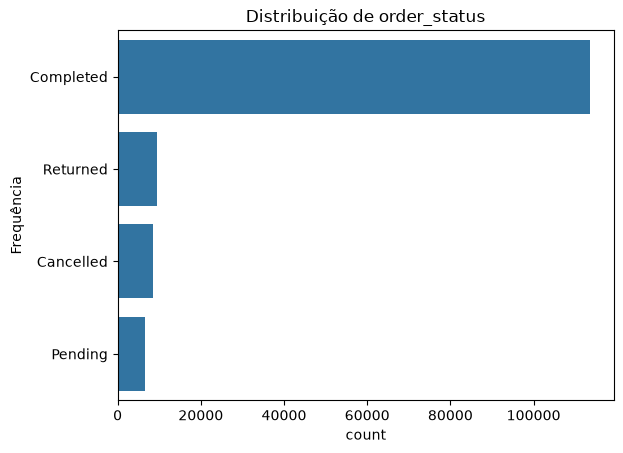

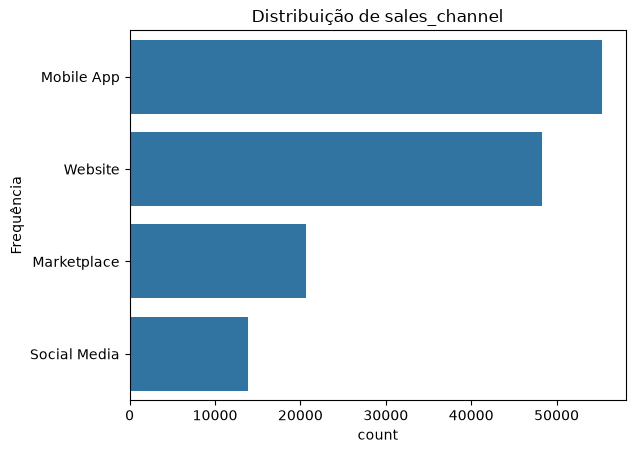

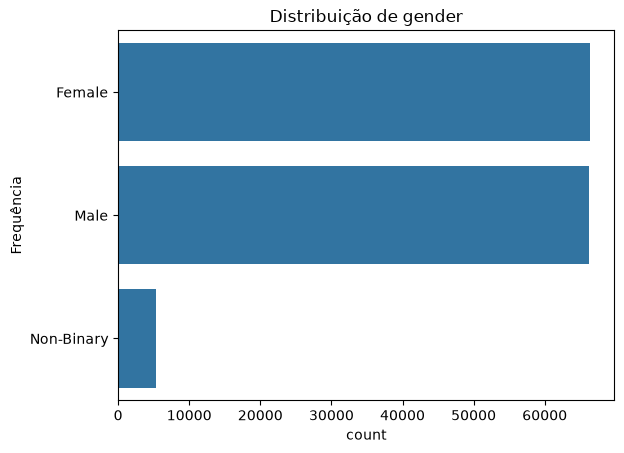

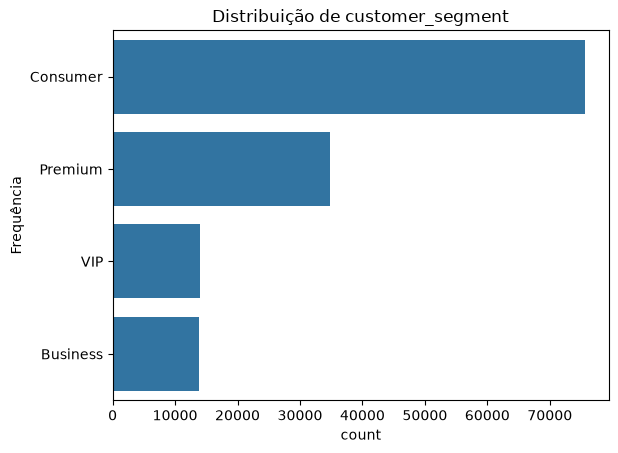

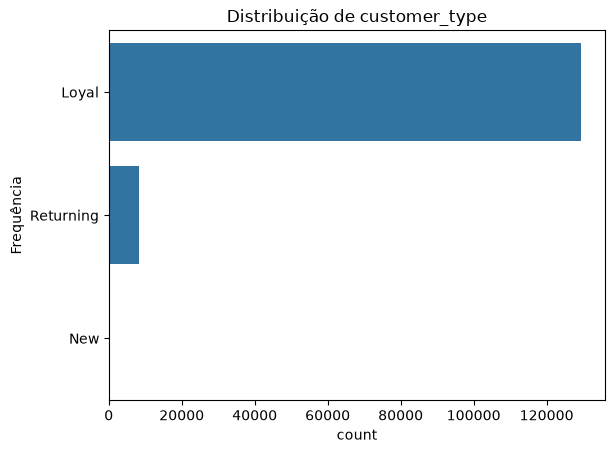

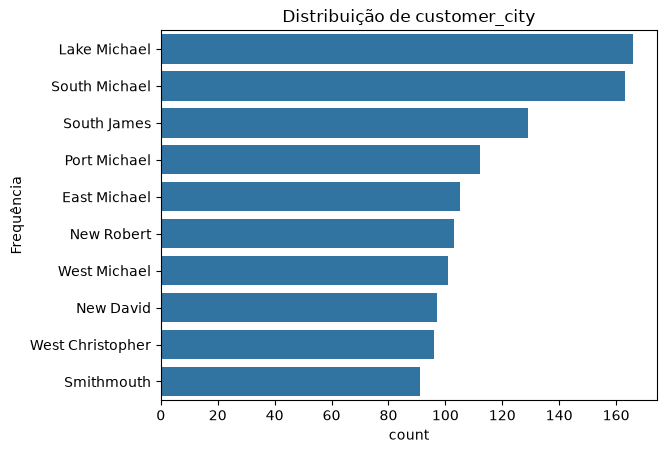

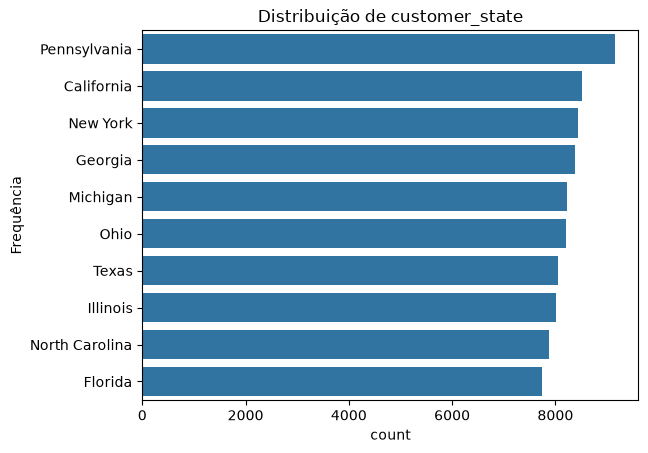

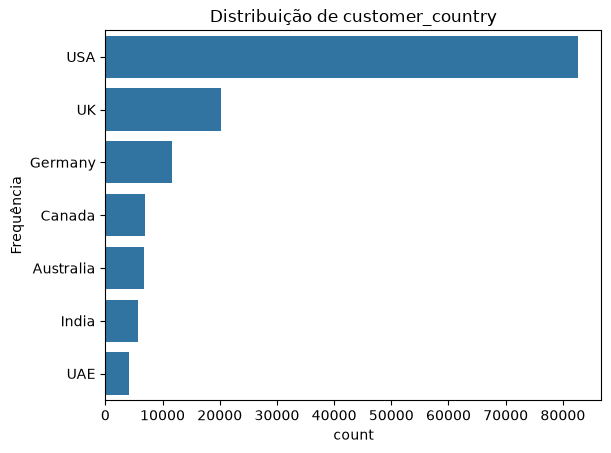

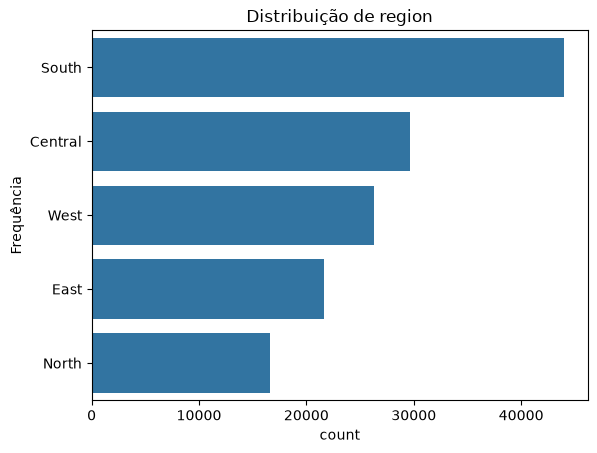

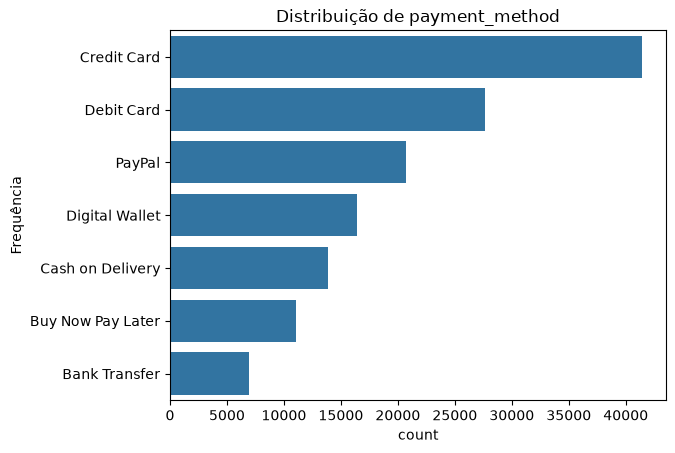

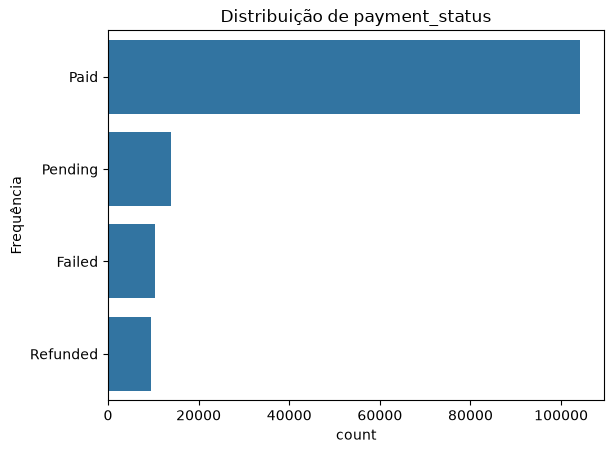

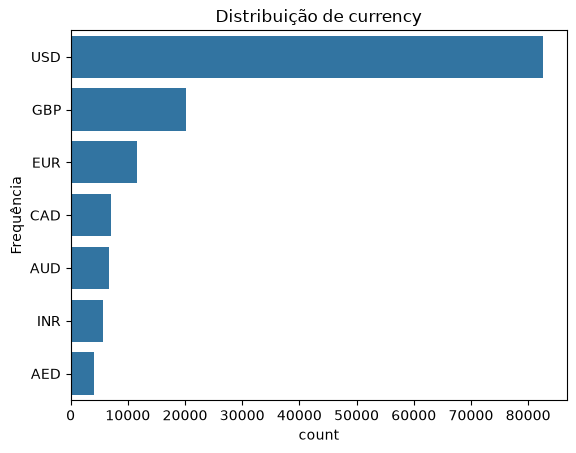

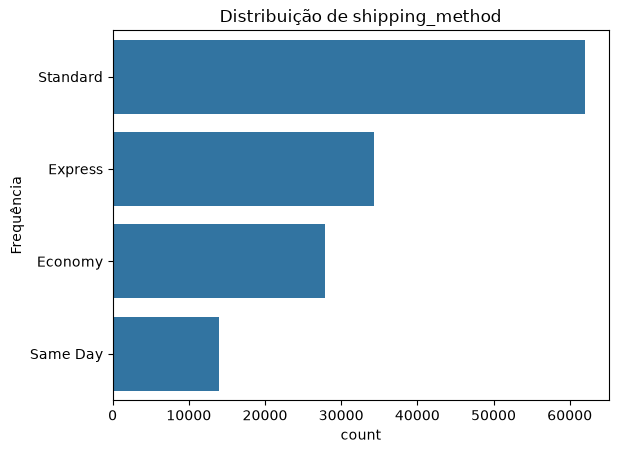

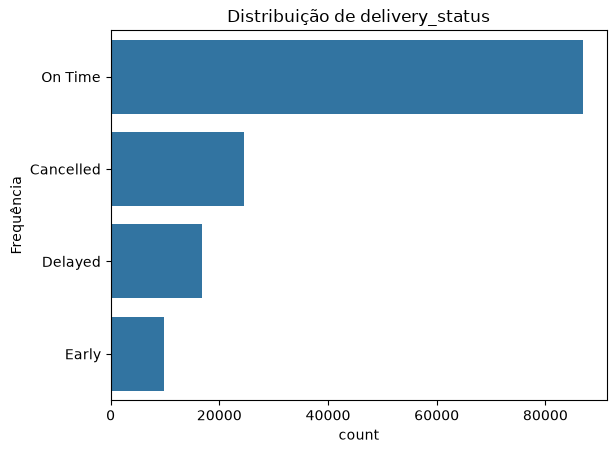

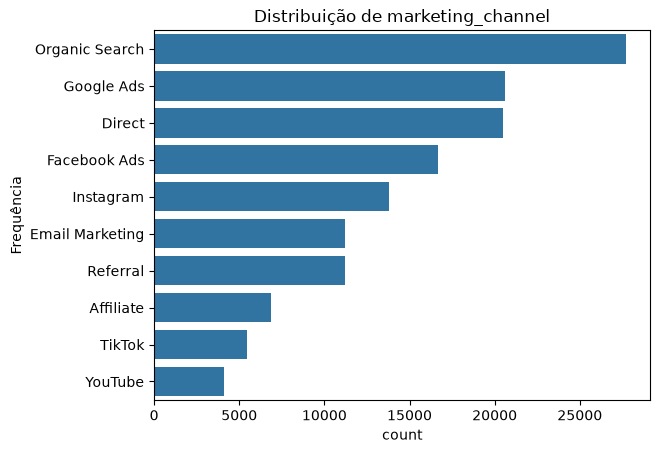

In [17]:
for coluna in cat.columns:
    aux = df[coluna].value_counts().head(10).reset_index()

    sns.barplot(
        data=aux,
        x='count',
        y=coluna
    )
    plt.title(f'Distribuição de {coluna}')
    plt.ylabel('Frequência')
    plt.show()

In [18]:
cat.columns

Index(['order_status', 'sales_channel', 'gender', 'customer_segment',
       'customer_type', 'customer_city', 'customer_state', 'customer_country',
       'region', 'payment_method', 'payment_status', 'currency',
       'shipping_method', 'delivery_status', 'marketing_channel'],
      dtype='str')

In [19]:
for coluna in cat.columns:
    print(coluna)

order_status
sales_channel
gender
customer_segment
customer_type
customer_city
customer_state
customer_country
region
payment_method
payment_status
currency
shipping_method
delivery_status
marketing_channel


# 2.0 Divisão entre Treino e Teste

In [44]:
df = pd.read_csv('../dataset/arquivo_pronto.csv')

In [45]:
df

,order_status,sales_channel,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,...,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
0,Pending,Mobile App,36,Male,Consumer,Loyal,Jessicaview,Northern Ireland,UK,West,...,1646.24,379.75,253.29,21.46,1541.24,1056.62,463.16,30.05,7757.75,5
1,Completed,Social Media,28,Female,Consumer,Loyal,Lake Kelly,Tamil Nadu,India,South,...,4522.55,1392.57,563.40,42.21,3735.59,2581.89,1111.49,29.75,25296.44,14
2,Completed,Website,26,Male,Premium,Loyal,New Lauraton,Texas,USA,South,...,624.36,56.09,39.78,3.66,611.71,289.88,318.17,52.01,4436.10,5
3,Returned,Mobile App,43,Male,Premium,Loyal,New John,Wales,UK,West,...,2470.88,0.00,494.17,19.12,2984.17,1520.65,1444.40,48.40,14476.00,9
4,Completed,Website,40,Female,Premium,Loyal,Paulachester,North Carolina,USA,South,...,1721.50,474.88,87.26,2.53,1336.41,838.40,495.48,37.08,10695.70,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,Completed,Website,50,Male,Premium,Loyal,Jocelynshire,Northern Ireland,UK,West,...,2789.47,762.81,405.33,2.48,2434.47,1666.02,765.97,31.46,10217.54,8
138112,Completed,Marketplace,37,Male,VIP,Loyal,East Lisamouth,North Carolina,USA,South,...,140.10,28.60,7.81,12.02,131.33,61.82,57.49,43.78,3211.66,4
138113,Completed,Website,74,Male,Premium,Returning,North Rodney,South Australia,Australia,South,...,2084.83,569.79,151.51,11.30,1677.85,1410.46,256.09,15.26,4387.17,3
138114,Completed,Marketplace,53,Female,Consumer,Returning,Rodriguezview,Georgia,USA,South,...,853.08,43.44,56.67,5.62,871.93,446.40,419.91,48.16,3150.03,2


In [46]:
x = df[['net_sales', 'tax_amount', 'gross_sales', 'profit_margin_percentage','product_cost', 'loyalty_points_earned', 'discount_amount', 'quantity', 'sales_channel', 'marketing_channel']]
y = df['profit']

In [47]:
x.describe()

,net_sales,tax_amount,gross_sales,profit_margin_percentage,product_cost,loyalty_points_earned,discount_amount,quantity
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,1282.503575,122.462933,1375.384176,45.065997,708.903449,103.991051,237.621614,5.615244
std,1169.274669,140.939368,1291.009554,13.120357,730.044970,115.175640,378.779459,3.371289
min,5.800000,0.340000,6.310000,-59.550000,1.970000,0.000000,0.000000,1.000000
25%,448.200000,34.650000,458.920000,38.880000,207.667500,17.000000,26.327500,3.000000
50%,950.760000,77.010000,995.730000,46.990000,478.955000,70.000000,103.285000,5.000000
75%,1744.582500,156.200000,1871.200000,53.770000,953.762500,151.000000,277.125000,8.000000
max,16218.000000,2091.520000,16051.190000,77.590000,9963.410000,1621.000000,6759.020000,24.000000


In [48]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [49]:
variaveis_numericas = x.select_dtypes(include=['int64', 'float']).columns
variaveis_categoricas = x.select_dtypes(exclude=['int64', 'float']).columns

# 3.0 Pré-processamento

In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), variaveis_numericas),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), variaveis_categoricas)
    ],
    remainder='passthrough'
)

# 4.0 Machine Learning

In [51]:
df_result = pd.DataFrame()

# 4.1 Decision Tree Regressor

In [52]:
dt = DecisionTreeRegressor(random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('dt', dt)
])

param_grid = {
    'dt__max_depth': [None, 2, 5, 10],
    'dt__min_samples_split': [2, 5, 10],
    'dt__min_samples_leaf': [1, 2, 10]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3
)

grid_search.fit(x_train, y_train)
y_pred = grid_search.predict(x_test)

rmse = root_mean_squared_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

result = pd.DataFrame({
    'modelo': ['DecisionTree'],
    'rmse': [rmse],
    'mse': [mse],
    'mae': [mae],
    'mape': [mape]
})

df_result = pd.concat([df_result, result], ignore_index=True)

In [53]:
df_result

,modelo,rmse,mse,mae,mape
0,DecisionTree,14.924974,222.754834,4.30781,0.010076


## 4.2 Linear Regression

In [56]:
lr = LinearRegression()

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('lr', lr)
])

param_grid = {
    'lr__fit_intercept': [True, False]
}

grid_lr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3
)

grid_lr.fit(x_train, y_train)
y_pred = grid_lr.predict(x_test)

rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

result = pd.DataFrame({
    'modelo': ['Linear Regression'],
    'rmse': [rmse],
    'mse': [mse],
    'mae': [mae],
    'mape': [mape]
})

df_result = pd.concat([df_result, result], ignore_index=True)
df_result

,modelo,rmse,mse,mae,mape
0,DecisionTree,1.492497e+01,2.227548e+02,4.307810e+00,1.007639e-02
1,Linear Regression,5.773950e-12,3.333850e-23,4.806887e-12,3.687442e-14
2,Linear Regression,5.773950e-12,3.333850e-23,4.806887e-12,3.687442e-14


In [57]:
joblib.dump(grid_lr.best_estimator_, '../modelo/modelo.joblib')

['../modelo/modelo.joblib']